In [87]:

from pathlib import Path
import pandas as pd

# Get the directory where Python is running
PROJECT_ROOT = Path.cwd()

# If running from src/, move up to the project root
if PROJECT_ROOT.name == "src":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Locate the first training dataset
dataset_path = PROJECT_ROOT / "data" / "train-00000-of-00002.parquet"

# Print only folder and file names, not absolute paths
print("Project folder:", PROJECT_ROOT.name)
print("Dataset file:", dataset_path.name)
print("File exists:", dataset_path.exists())


Project folder: lstm project 2
Dataset file: train-00000-of-00002.parquet
File exists: True


In [4]:
df = pd.read_parquet(dataset_path)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

Dataset shape: (900675, 1)
Column names: ['text']


In [5]:
# Display the first 5 text records
df.head()

,text
0,
1,= Valkyria Chronicles III = \n
2,
3,Senjō no Valkyria 3 : Unrecorded Chronicles (...
4,"The game began development in 2010 , carrying..."


In [7]:

# Count empty or whitespace-only rows
is_empty = df["text"].fillna("").str.strip().eq("")

print("Total rows:", len(df))
print("Empty rows:", is_empty.sum())
print("Non-empty rows:", (~is_empty).sum())


Total rows: 900675
Empty rows: 318165
Non-empty rows: 582510


In [8]:
# Calculate the number of characters in each text record
text_lengths = df["text"].fillna("").str.len()

print("Average characters per row:", round(text_lengths.mean(), 2))
print("Longest row (characters):", text_lengths.max())
print("Shortest row (characters):", text_lengths.min())

Average characters per row: 298.79
Longest row (characters): 4996
Shortest row (characters): 0


In [9]:

# Select the first 10 non-empty text records
non_empty_texts = df.loc[
    df["text"].fillna("").str.strip().ne(""),
    "text"
]

for i, text in enumerate(non_empty_texts.head(10), start=1):
    print(f"\n--- Record {i} ---")
    print(text[:300])



--- Record 1 ---
 = Valkyria Chronicles III = 


--- Record 2 ---
 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in Janu

--- Record 3 ---
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers . Character designer Raita Hon

--- Record 4 ---
 It met with positive sales in Japan , and was praised by both Japanese and western critics . After release , it received downloadable content , along with an expanded edition in November of that year . It was also adapted into manga and an original video animation series . Due to low sales of 

In [10]:

# Combine the first 1,000 non-empty records into one text sample
sample_texts = non_empty_texts.head(1000).tolist()

sample_text = "\n".join(sample_texts)

print("Number of records:", len(sample_texts))
print("Total characters:", len(sample_text))
print("\nFirst 1,000 characters:\n")
print(sample_text[:1000])


Number of records: 1000
Total characters: 470630

First 1,000 characters:

 = Valkyria Chronicles III = 

 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 

 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent 

In [11]:

# Split the sample text wherever whitespace occurs
tokens = sample_text.split()

print("First 30 tokens:")
print(tokens[:30])

print("\nTotal tokens:", len(tokens))
print("Unique tokens:", len(set(tokens)))


First 30 tokens:
['=', 'Valkyria', 'Chronicles', 'III', '=', 'Senjō', 'no', 'Valkyria', '3', ':', 'Unrecorded', 'Chronicles', '(', 'Japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'Valkyria', 'of', 'the', 'Battlefield', '3', ')', ',', 'commonly', 'referred', 'to', 'as']

Total tokens: 88023
Unique tokens: 11886


In [12]:

from collections import Counter

# Count how often each token appears
token_counts = Counter(tokens)

# Reserve ID 0 for unknown or padding tokens
word_to_id = {"<UNK>": 0}

# Assign an ID to each unique token
for word in token_counts:
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

# Create the reverse mapping: ID -> word
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Vocabulary size:", len(word_to_id))
print("\nFirst 10 vocabulary entries:")
print(list(word_to_id.items())[:10])

print("\nExample conversion:")
example_words = tokens[:10]
example_ids = [word_to_id[word] for word in example_words]

print("Words:", example_words)
print("IDs:  ", example_ids)


Vocabulary size: 11887

First 10 vocabulary entries:
[('<UNK>', 0), ('=', 1), ('Valkyria', 2), ('Chronicles', 3), ('III', 4), ('Senjō', 5), ('no', 6), ('3', 7), (':', 8), ('Unrecorded', 9)]

Example conversion:
Words: ['=', 'Valkyria', 'Chronicles', 'III', '=', 'Senjō', 'no', 'Valkyria', '3', ':']
IDs:   [1, 2, 3, 4, 1, 5, 6, 2, 7, 8]


In [13]:

# Convert all tokens into integer IDs
token_ids = [word_to_id[word] for word in tokens]

# Use the previous 5 tokens to predict the next token
sequence_length = 5

X = []
y = []

for i in range(len(token_ids) - sequence_length):
    X.append(token_ids[i:i + sequence_length])
    y.append(token_ids[i + sequence_length])

print("Number of training examples:", len(X))
print("Input sequence length:", len(X[0]))
print("First input IDs:", X[0])
print("Target ID:", y[0])

# Convert the first example back into words
print("\nInput words:", [id_to_word[idx] for idx in X[0]])
print("Target word:", id_to_word[y[0]])


Number of training examples: 88018
Input sequence length: 5
First input IDs: [1, 2, 3, 4, 1]
Target ID: 5

Input words: ['=', 'Valkyria', 'Chronicles', 'III', '=']
Target word: Senjō


In [14]:

# Inspect the first 10 non-empty records
for i, text in enumerate(non_empty_texts.head(10), start=1):
    words = text.split()

    print(f"\nRecord {i}")
    print("Word count:", len(words))
    print("Beginning:", words[:12])



Record 1
Word count: 5
Beginning: ['=', 'Valkyria', 'Chronicles', 'III', '=']

Record 2
Word count: 127
Beginning: ['Senjō', 'no', 'Valkyria', '3', ':', 'Unrecorded', 'Chronicles', '(', 'Japanese', ':', '戦場のヴァルキュリア3', ',']

Record 3
Word count: 91
Beginning: ['The', 'game', 'began', 'development', 'in', '2010', ',', 'carrying', 'over', 'a', 'large', 'portion']

Record 4
Word count: 101
Beginning: ['It', 'met', 'with', 'positive', 'sales', 'in', 'Japan', ',', 'and', 'was', 'praised', 'by']

Record 5
Word count: 5
Beginning: ['=', '=', 'Gameplay', '=', '=']

Record 6
Word count: 211
Beginning: ['As', 'with', 'previous', 'Valkyira', 'Chronicles', 'games', ',', 'Valkyria', 'Chronicles', 'III', 'is', 'a']

Record 7
Word count: 296
Beginning: ['The', 'game', "'s", 'battle', 'system', ',', 'the', 'BliTZ', 'system', ',', 'is', 'carried']

Record 8
Word count: 84
Beginning: ['Troops', 'are', 'divided', 'into', 'five', 'classes', ':', 'Scouts', ',', 'Shocktroopers', ',', 'Engineers']

Record 9


In [15]:

sequence_length = 5

X = []
y = []

# Process each record independently to avoid crossing boundaries
for text in non_empty_texts.head(1000):
    record_tokens = text.split()

    # Skip records that are too short to create an example
    if len(record_tokens) <= sequence_length:
        continue

    # Convert words to IDs using our existing vocabulary
    record_ids = [word_to_id[word] for word in record_tokens]

    # Create input sequences and their next-word targets
    for i in range(len(record_ids) - sequence_length):
        X.append(record_ids[i:i + sequence_length])
        y.append(record_ids[i + sequence_length])

print("Training examples:", len(X))
print("Input length:", sequence_length)

print("\nFirst input:", [id_to_word[idx] for idx in X[0]])
print("Target:", id_to_word[y[0]])


Training examples: 83063
Input length: 5

First input: ['Senjō', 'no', 'Valkyria', '3', ':']
Target: Unrecorded


In [16]:

from sklearn.model_selection import train_test_split

# Keep the same 1,000-record experiment
records = non_empty_texts.head(1000).tolist()

# Split records before creating sequences
train_records, val_records = train_test_split(
    records,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(train_records))
print("Validation records:", len(val_records))


Training records: 800
Validation records: 200


In [17]:

from collections import Counter

# Tokenize the training records only
train_tokens = []

for text in train_records:
    train_tokens.extend(text.split())

# Count token frequencies in the training data
token_counts = Counter(train_tokens)

# Reserve ID 0 for unknown tokens
word_to_id = {"<UNK>": 0}

# Assign an integer ID to each training token
for word in token_counts:
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

# Create the reverse mapping
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Training token occurrences:", len(train_tokens))
print("Training vocabulary size:", len(word_to_id))
print("Most common 10 tokens:")
print(token_counts.most_common(10))


Training token occurrences: 69156
Training vocabulary size: 10371
Most common 10 tokens:
[('the', 3911), (',', 3493), ('.', 2528), ('of', 1998), ('and', 1726), ('in', 1315), ('to', 1283), ('a', 1185), ('=', 981), ('"', 768)]


In [18]:

def create_sequences(records, word_to_id, sequence_length=5):
    X = []
    y = []

    for text in records:
        tokens_in_record = text.split()

        # Convert unknown words to ID 0
        ids = [word_to_id.get(word, 0) for word in tokens_in_record]

        for i in range(len(ids) - sequence_length):
            X.append(ids[i:i + sequence_length])
            y.append(ids[i + sequence_length])

    return X, y


X_train, y_train = create_sequences(
    train_records, word_to_id, sequence_length=5
)

X_val, y_val = create_sequences(
    val_records, word_to_id, sequence_length=5
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Vocabulary size:", len(word_to_id))


Training examples: 65187
Validation examples: 17876
Vocabulary size: 10371


In [19]:

import torch

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1
MPS available: True
CUDA available: False


In [20]:

import torch
from torch.utils.data import TensorDataset, DataLoader

# Select the best available device
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

# Convert lists into integer tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

print("Training input shape:", X_train_tensor.shape)
print("Training target shape:", y_train_tensor.shape)
print("Validation input shape:", X_val_tensor.shape)
print("Validation target shape:", y_val_tensor.shape)


Using device: mps
Training input shape: torch.Size([65187, 5])
Training target shape: torch.Size([65187])
Validation input shape: torch.Size([17876, 5])
Validation target shape: torch.Size([17876])


In [21]:

batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 1019
Validation batches: 280


In [22]:

import torch.nn as nn

class NextWordLSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=256
    ):
        super().__init__()

        # Convert token IDs into dense vectors
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # Learn patterns in the sequence
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Predict a score for every vocabulary token
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        # Output shape: batch_size × sequence_length × hidden_dim
        lstm_output, (hidden_state, cell_state) = self.lstm(embedded)

        # Use the output corresponding to the final input token
        last_output = lstm_output[:, -1, :]

        # Return raw scores (logits) for every vocabulary token
        logits = self.fc(last_output)

        return logits


vocab_size = len(word_to_id)

model = NextWordLSTM(vocab_size).to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)
print("Vocabulary size:", vocab_size)


NextWordLSTM(
  (embedding): Embedding(10371, 128)
  (lstm): LSTM(128, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=10371, bias=True)
)

Model device: mps:0
Vocabulary size: 10371


In [23]:

import torch.optim as optim

# Measures how far the predicted scores are from the correct next token
criterion = nn.CrossEntropyLoss()

# Updates model parameters to reduce prediction error
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [24]:

# Get one batch of training examples
X_batch, y_batch = next(iter(train_loader))

# Move the batch to the Apple GPU
X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# Put the model in evaluation mode
model.eval()

# Make predictions without calculating gradients
with torch.no_grad():
    predictions = model(X_batch)
    loss = criterion(predictions, y_batch)

print("Input batch shape:", X_batch.shape)
print("Prediction shape:", predictions.shape)
print("Target batch shape:", y_batch.shape)
print("Initial loss:", loss.item())


Input batch shape: torch.Size([64, 5])
Prediction shape: torch.Size([64, 10371])
Target batch shape: torch.Size([64])
Initial loss: 9.249641418457031


In [25]:

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        # Move data to the selected device
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients left over from the previous batch
        optimizer.zero_grad()

        # Predict the next token
        predictions = model(X_batch)

        # Calculate prediction error
        loss = criterion(predictions, y_batch)

        # Calculate gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    return average_loss


print("Training function defined successfully.")


Training function defined successfully.


In [26]:

import time

start_time = time.time()

train_loss = train_one_epoch(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

elapsed_time = time.time() - start_time

print(f"Training loss: {train_loss:.4f}")
print(f"Time taken: {elapsed_time:.2f} seconds")


Training loss: 6.8978
Time taken: 12.39 seconds


In [27]:

def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            total_loss += loss.item()

            predicted_tokens = predictions.argmax(dim=1)
            total_correct += (predicted_tokens == y_batch).sum().item()
            total_examples += y_batch.size(0)

    average_loss = total_loss / len(data_loader)
    accuracy = total_correct / total_examples

    return average_loss, accuracy


val_loss, val_accuracy = evaluate_model(
    model, val_loader, criterion, device
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.2%}")


Validation loss: 6.6274
Validation accuracy: 12.87%


In [28]:

num_epochs = 4

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    start_time = time.time()

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed_time = time.time() - start_time

    print(
        f"Epoch {epoch + 2}/{num_epochs + 1} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%} | "
        f"Time: {elapsed_time:.2f}s"
    )


Epoch 2/5 | Train Loss: 5.8413 | Val Loss: 6.5280 | Val Accuracy: 14.74% | Time: 11.70s
Epoch 3/5 | Train Loss: 4.9589 | Val Loss: 6.5666 | Val Accuracy: 15.78% | Time: 11.41s
Epoch 4/5 | Train Loss: 4.0745 | Val Loss: 6.7471 | Val Accuracy: 15.95% | Time: 11.94s
Epoch 5/5 | Train Loss: 3.2580 | Val Loss: 6.9416 | Val Accuracy: 15.76% | Time: 11.79s


In [88]:


from pathlib import Path

# Create the models folder inside the project directory
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Define the model filename
model_path = model_dir / "lstm_baseline.pt"

# Save the trained model weights
torch.save(model.state_dict(), model_path)

# Display only the filename, not your full computer path
print("Model saved successfully:", model_path.name)



Model saved successfully: lstm_baseline.pt


In [30]:

import copy

# Start a fresh model for this experiment
model = NextWordLSTM(vocab_size).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

best_val_loss = float("inf")
best_state = None
patience = 2
epochs_without_improvement = 0
max_epochs = 10

history_early = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(max_epochs):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    history_early["train_loss"].append(train_loss)
    history_early["val_loss"].append(val_loss)
    history_early["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

        torch.save(best_state, model_path)
        epochs_without_improvement = 0
        status = "Saved best model"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/{patience})"

    print(
        f"Epoch {epoch + 1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%} | "
        f"{status}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best weights in memory, too
model.load_state_dict(best_state)

print(f"\nBest validation loss: {best_val_loss:.4f}")
print("Best model restored.")


Epoch 1/10 | Train Loss: 6.8946 | Val Loss: 6.6379 | Val Accuracy: 12.69% | Saved best model
Epoch 2/10 | Train Loss: 5.8203 | Val Loss: 6.5568 | Val Accuracy: 15.00% | Saved best model
Epoch 3/10 | Train Loss: 4.9434 | Val Loss: 6.6201 | Val Accuracy: 15.40% | No improvement (1/2)
Epoch 4/10 | Train Loss: 4.0625 | Val Loss: 6.7634 | Val Accuracy: 16.05% | No improvement (2/2)
Early stopping triggered.

Best validation loss: 6.5568
Best model restored.


In [31]:

data_dir = PROJECT_ROOT / "data"

for file_path in sorted(data_dir.glob("*.parquet")):
    print(
        f"{file_path.name}: "
        f"{file_path.stat().st_size / (1024 ** 2):.2f} MB"
    )


test-00000-of-00001.parquet: 0.70 MB
train-00000-of-00002.parquet: 149.72 MB
train-00001-of-00002.parquet: 149.81 MB
validation-00000-of-00001.parquet: 0.63 MB


In [32]:

validation_path = PROJECT_ROOT / "data" / "validation-00000-of-00001.parquet"

validation_df = pd.read_parquet(validation_path)

print("Validation shape:", validation_df.shape)
print("Columns:", validation_df.columns.tolist())
print("\nFirst five records:")
display(validation_df.head())


Validation shape: (3760, 1)
Columns: ['text']

First five records:


,text
0,
1,= Homarus gammarus = \n
2,
3,"Homarus gammarus , known as the European lobs..."
4,


In [33]:

validation_texts = (
    validation_df["text"]
    .fillna("")
    .str.strip()
)

print("Total rows:", len(validation_texts))
print("Empty rows:", validation_texts.eq("").sum())
print("Non-empty rows:", validation_texts.ne("").sum())
print("Total characters:", validation_texts.str.len().sum())


Total rows: 3760
Empty rows: 1299
Non-empty rows: 2461
Total characters: 1134764


In [34]:

# Keep only non-empty validation records
official_val_records = validation_df.loc[
    validation_df["text"].fillna("").str.strip().ne(""),
    "text"
].str.strip().tolist()

print("Official validation records:", len(official_val_records))
print("\nFirst validation record:")
print(official_val_records[0][:300])


Official validation records: 2461

First validation record:
= Homarus gammarus =


In [35]:

train_shard_2_path = PROJECT_ROOT / "data" / "train-00001-of-00002.parquet"

train_shard_2_sample = pd.read_parquet(
    train_shard_2_path,
    columns=["text"]
).head(5)

print("Second training shard — first five records:")
display(train_shard_2_sample)


Second training shard — first five records:


,text
0,( * ) Denotes co @-@ producer . \n
1,
2,= = Credits and personnel = = \n
3,
4,Credits adapted from Allmusic . \n


In [36]:

train_shard_1_path = PROJECT_ROOT / "data" / "train-00000-of-00002.parquet"

for path in [train_shard_1_path, train_shard_2_path]:
    shard_df = pd.read_parquet(path, columns=["text"])

    text_column = shard_df["text"].fillna("").str.strip()
    non_empty_count = text_column.ne("").sum()

    print(f"\nFile: {path.name}")
    print("Total rows:", len(shard_df))
    print("Non-empty rows:", non_empty_count)
    print("Total characters:", text_column.str.len().sum())

    del shard_df



File: train-00000-of-00002.parquet
Total rows: 900675
Non-empty rows: 582510
Total characters: 267369238

File: train-00001-of-00002.parquet
Total rows: 900675
Non-empty rows: 582519
Total characters: 267429939


In [37]:

import re

def clean_text(text):
    # Handle missing values
    if not isinstance(text, str):
        return ""

    # Remove whitespace from the beginning and end
    text = text.strip()

    # Normalize repeated whitespace to a single space
    text = re.sub(r"\s+", " ", text)

    return text


In [38]:
clean_text("  Hello   world . \n")

'Hello world .'

In [39]:

for original_text in train_shard_2_sample["text"].fillna("").head(5):
    cleaned_text = clean_text(original_text)

    print("BEFORE:", repr(original_text))
    print("AFTER: ", repr(cleaned_text))
    print("-" * 50)


BEFORE: ' ( * ) Denotes co @-@ producer . \n'
AFTER:  '( * ) Denotes co @-@ producer .'
--------------------------------------------------
BEFORE: ''
AFTER:  ''
--------------------------------------------------
BEFORE: ' = = Credits and personnel = = \n'
AFTER:  '= = Credits and personnel = ='
--------------------------------------------------
BEFORE: ''
AFTER:  ''
--------------------------------------------------
BEFORE: ' Credits adapted from Allmusic . \n'
AFTER:  'Credits adapted from Allmusic .'
--------------------------------------------------


In [40]:

# Clean the official validation records we already loaded
official_val_records = [
    clean_text(text)
    for text in validation_df["text"]
]

# Remove records that are empty after cleaning
official_val_records = [
    text for text in official_val_records if text
]

print("Cleaned validation records:", len(official_val_records))
print("\nFirst five cleaned records:")
for text in official_val_records[:5]:
    print(repr(text[:120]))


Cleaned validation records: 2461

First five cleaned records:
'= Homarus gammarus ='
'Homarus gammarus , known as the European lobster or common lobster , is a species of clawed lobster from the eastern Atl'
'= = Description = ='
'Homarus gammarus is a large crustacean , with a body length up to 60 centimetres ( 24 in ) and weighing up to 5 – 6 kilo'
'The first pair of pereiopods is armed with a large , asymmetrical pair of claws . The larger one is the " crusher " , an'


In [41]:

train_paths = [
    PROJECT_ROOT / "data" / "train-00000-of-00002.parquet",
    PROJECT_ROOT / "data" / "train-00001-of-00002.parquet"
]

training_records = []

for path in train_paths:
    shard_df = pd.read_parquet(path, columns=["text"])

    # Clean every record
    cleaned = shard_df["text"].map(clean_text)

    # Remove empty records and select a manageable sample
    non_empty = cleaned[cleaned.ne("")]
    selected = non_empty.head(2000).tolist()

    training_records.extend(selected)

    print(f"{path.name}: selected {len(selected)} records")

    del shard_df, cleaned, non_empty

print("\nTotal training records:", len(training_records))
print("Example:", repr(training_records[0][:150]))


train-00000-of-00002.parquet: selected 2000 records
train-00001-of-00002.parquet: selected 2000 records

Total training records: 4000
Example: '= Valkyria Chronicles III ='


In [42]:

from collections import Counter

# Collect tokens only from the training records
train_tokens = []

for text in training_records:
    train_tokens.extend(text.split())

# Count token frequencies
token_counts = Counter(train_tokens)

# Reserve ID 0 for unknown words
word_to_id = {"<UNK>": 0}

for word, count in token_counts.items():
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

# Reverse lookup: token ID -> token
id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

vocab_size = len(word_to_id)

print("Training token occurrences:", len(train_tokens))
print("Vocabulary size:", vocab_size)
print("\nMost common 10 tokens:")
print(token_counts.most_common(10))


Training token occurrences: 364765
Vocabulary size: 27848

Most common 10 tokens:
[('the', 20152), (',', 18341), ('.', 12901), ('of', 9760), ('and', 8656), ('to', 7042), ('in', 6722), ('a', 6106), ('"', 5111), ('=', 5017)]


In [43]:

def create_sequences(records, word_to_id, sequence_length=5):
    X = []
    y = []

    for text in records:
        tokens_in_record = text.split()

        # Convert words into IDs; unseen words become <UNK> (ID 0)
        ids = [word_to_id.get(word, 0) for word in tokens_in_record]

        # Predict the next token using the previous five
        for i in range(len(ids) - sequence_length):
            X.append(ids[i:i + sequence_length])
            y.append(ids[i + sequence_length])

    return X, y


sequence_length = 5

X_train, y_train = create_sequences(
    training_records, word_to_id, sequence_length
)

X_val, y_val = create_sequences(
    official_val_records, word_to_id, sequence_length
)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Sequence length:", sequence_length)
print("Vocabulary size:", vocab_size)


Training examples: 345035
Validation examples: 201687
Sequence length: 5
Vocabulary size: 27848


In [44]:

# Count validation tokens that are not in the training vocabulary
total_val_tokens = 0
unknown_val_tokens = 0

for text in official_val_records:
    for word in text.split():
        total_val_tokens += 1

        if word not in word_to_id:
            unknown_val_tokens += 1

unknown_percentage = (
    unknown_val_tokens / total_val_tokens * 100
    if total_val_tokens else 0
)

print("Total validation tokens:", total_val_tokens)
print("Unknown validation tokens:", unknown_val_tokens)
print(f"Unknown-token percentage: {unknown_percentage:.2f}%")


Total validation tokens: 213886
Unknown validation tokens: 17581
Unknown-token percentage: 8.22%


In [45]:

import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

X_train_tensor = torch.tensor(X_train, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

print("Device:", device)
print("Training inputs:", X_train_tensor.shape)
print("Training targets:", y_train_tensor.shape)
print("Validation inputs:", X_val_tensor.shape)
print("Validation targets:", y_val_tensor.shape)


Device: mps
Training inputs: torch.Size([345035, 5])
Training targets: torch.Size([345035])
Validation inputs: torch.Size([201687, 5])
Validation targets: torch.Size([201687])


In [46]:

from torch.utils.data import TensorDataset, DataLoader

batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Batch size:", batch_size)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Batch size: 64
Training batches: 5392
Validation batches: 3152


In [47]:

import torch.nn as nn
import torch.optim as optim

class NextWordLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        lstm_output, (hidden_state, cell_state) = self.lstm(embedded)

        last_output = lstm_output[:, -1, :]
        logits = self.fc(last_output)

        return logits


model = NextWordLSTM(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)
print("\nDevice:", next(model.parameters()).device)
print("Vocabulary size:", vocab_size)


NextWordLSTM(
  (embedding): Embedding(27848, 128)
  (lstm): LSTM(128, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=27848, bias=True)
)

Device: mps:0
Vocabulary size: 27848


In [48]:

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

model.eval()

with torch.no_grad():
    predictions = model(X_batch)
    loss = criterion(predictions, y_batch)

print("Input shape:", X_batch.shape)
print("Prediction shape:", predictions.shape)
print("Target shape:", y_batch.shape)
print("Initial loss:", round(loss.item(), 4))


Input shape: torch.Size([64, 5])
Prediction shape: torch.Size([64, 27848])
Target shape: torch.Size([64])
Initial loss: 10.2408


In [49]:

import time

model.train()

total_loss = 0.0
total_correct = 0
total_examples = 0

start_time = time.time()

for batch_idx, (X_batch, y_batch) in enumerate(train_loader, start=1):
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    # Clear gradients from the previous batch
    optimizer.zero_grad()

    # Predict the next word
    predictions = model(X_batch)

    # Compare predictions with the correct answers
    loss = criterion(predictions, y_batch)

    # Calculate gradients and update model parameters
    loss.backward()
    optimizer.step()

    # Track performance across the whole epoch
    batch_size_now = y_batch.size(0)
    total_loss += loss.item() * batch_size_now
    total_correct += (predictions.argmax(dim=1) == y_batch).sum().item()
    total_examples += batch_size_now

    if batch_idx % 500 == 0 or batch_idx == len(train_loader):
        print(
            f"Batch {batch_idx}/{len(train_loader)} | "
            f"Average loss: {total_loss / total_examples:.4f}"
        )

training_loss = total_loss / total_examples
training_accuracy = total_correct / total_examples
elapsed_time = time.time() - start_time

print("\nTraining complete!")
print(f"Training loss: {training_loss:.4f}")
print(f"Training accuracy: {training_accuracy:.2%}")
print(f"Time taken: {elapsed_time / 60:.2f} minutes")


Batch 500/5392 | Average loss: 7.5671
Batch 1000/5392 | Average loss: 7.2806
Batch 1500/5392 | Average loss: 7.1262
Batch 2000/5392 | Average loss: 7.0150
Batch 2500/5392 | Average loss: 6.9306
Batch 3000/5392 | Average loss: 6.8632
Batch 3500/5392 | Average loss: 6.8030
Batch 4000/5392 | Average loss: 6.7500
Batch 4500/5392 | Average loss: 6.7044
Batch 5000/5392 | Average loss: 6.6618
Batch 5392/5392 | Average loss: 6.6315

Training complete!
Training loss: 6.6315
Training accuracy: 13.86%
Time taken: 2.05 minutes


In [50]:

model.eval()

val_total_loss = 0.0
val_total_correct = 0
val_total_examples = 0

start_time = time.time()

with torch.no_grad():
    for batch_idx, (X_batch, y_batch) in enumerate(val_loader, start=1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        current_batch_size = y_batch.size(0)
        val_total_loss += loss.item() * current_batch_size
        val_total_correct += (
            predictions.argmax(dim=1) == y_batch
        ).sum().item()
        val_total_examples += current_batch_size

        if batch_idx % 500 == 0 or batch_idx == len(val_loader):
            print(f"Validation batch {batch_idx}/{len(val_loader)}")

validation_loss = val_total_loss / val_total_examples
validation_accuracy = val_total_correct / val_total_examples

print("\nValidation complete!")
print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation top-1 accuracy: {validation_accuracy:.2%}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")


Validation batch 500/3152
Validation batch 1000/3152
Validation batch 1500/3152
Validation batch 2000/3152
Validation batch 2500/3152
Validation batch 3000/3152
Validation batch 3152/3152

Validation complete!
Validation loss: 6.7497
Validation top-1 accuracy: 15.40%
Time taken: 0.36 minutes


In [51]:

# Train for epoch 2
model.train()

total_loss = 0.0
total_correct = 0
total_examples = 0

start_time = time.time()

for batch_idx, (X_batch, y_batch) in enumerate(train_loader, start=1):
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    optimizer.zero_grad()

    predictions = model(X_batch)
    loss = criterion(predictions, y_batch)

    loss.backward()
    optimizer.step()

    batch_size_now = y_batch.size(0)
    total_loss += loss.item() * batch_size_now
    total_correct += (predictions.argmax(dim=1) == y_batch).sum().item()
    total_examples += batch_size_now

training_loss = total_loss / total_examples
training_accuracy = total_correct / total_examples

print("Epoch 2 training complete")
print(f"Training loss: {training_loss:.4f}")
print(f"Training accuracy: {training_accuracy:.2%}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")


Epoch 2 training complete
Training loss: 5.5796
Training accuracy: 18.61%
Time taken: 2.09 minutes


In [52]:

model.eval()

val_total_loss = 0.0
val_total_correct = 0
val_total_examples = 0

start_time = time.time()

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        batch_size_now = y_batch.size(0)
        val_total_loss += loss.item() * batch_size_now
        val_total_correct += (
            predictions.argmax(dim=1) == y_batch
        ).sum().item()
        val_total_examples += batch_size_now

validation_loss = val_total_loss / val_total_examples
validation_accuracy = val_total_correct / val_total_examples

print("Epoch 2 validation complete")
print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation top-1 accuracy: {validation_accuracy:.2%}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")


Epoch 2 validation complete
Validation loss: 6.9585
Validation top-1 accuracy: 16.33%
Time taken: 0.35 minutes


In [89]:

from pathlib import Path

checkpoint_dir = PROJECT_ROOT / "models"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "lstm_wikitext_sample.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "vocab_size": vocab_size,
        "embedding_dim": 128,
        "hidden_dim": 256,
        "sequence_length": sequence_length,
        "word_to_id": word_to_id,
        "epoch": 2,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path.name)
print(f"Saved validation loss: {validation_loss:.4f}")


Checkpoint saved: lstm_wikitext_sample.pt
Saved validation loss: 5.5210


In [54]:

import torch.nn.functional as F

def predict_next_words(text, model, word_to_id, id_to_word, top_k=5):
    model.eval()

    # Clean and split the user's input
    text = clean_text(text)
    words = text.split()

    # The model expects exactly sequence_length input words
    words = words[-sequence_length:]

    if len(words) < sequence_length:
        print(f"Please enter at least {sequence_length} words.")
        return

    # Convert words to token IDs; unseen words become <UNK>
    input_ids = [word_to_id.get(word, 0) for word in words]

    # Add a batch dimension: [sequence_length] -> [1, sequence_length]
    input_tensor = torch.tensor(
        [input_ids], dtype=torch.long, device=device
    )

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = F.softmax(logits, dim=1)
        top_probs, top_ids = torch.topk(probabilities, top_k, dim=1)

    print("Input:", " ".join(words))
    print("\nTop predictions:")

    for token_id, probability in zip(
        top_ids[0].tolist(), top_probs[0].tolist()
    ):
        print(f"{id_to_word[token_id]:<20} {probability:.2%}")


predict_next_words(
    "the history of the",
    model,
    word_to_id,
    id_to_word,
    top_k=5,
)


Please enter at least 5 words.


In [55]:

predict_next_words(
    "the history of the world",
    model,
    word_to_id,
    id_to_word,
    top_k=5,
)


Input: the history of the world

Top predictions:
.                    23.41%
,                    13.31%
's                   7.57%
and                  5.83%
of                   3.37%


In [56]:

model.eval()

total_examples = 0
top1_correct = 0
top5_correct = 0

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)

        # Highest-scoring single prediction
        top1_predictions = logits.argmax(dim=1)
        top1_correct += (top1_predictions == y_batch).sum().item()

        # Five highest-scoring predictions
        top5_predictions = logits.topk(5, dim=1).indices
        matches = (top5_predictions == y_batch.unsqueeze(1)).any(dim=1)
        top5_correct += matches.sum().item()

        total_examples += y_batch.size(0)

top1_accuracy = top1_correct / total_examples
top5_accuracy = top5_correct / total_examples

print(f"Validation examples: {total_examples:,}")
print(f"Top-1 accuracy: {top1_accuracy:.2%}")
print(f"Top-5 accuracy: {top5_accuracy:.2%}")


Validation examples: 201,687
Top-1 accuracy: 16.33%
Top-5 accuracy: 32.05%


In [57]:

unknown_targets = 0
total_targets = 0

for text in official_val_records:
    token_ids = [
        word_to_id.get(word, 0)
        for word in text.split()
    ]

    for i in range(sequence_length, len(token_ids)):
        target_id = token_ids[i]
        total_targets += 1

        if target_id == word_to_id["<UNK>"]:
            unknown_targets += 1

print(f"Validation targets: {total_targets:,}")
print(f"Unknown targets: {unknown_targets:,}")
print(f"Unknown target rate: {unknown_targets / total_targets:.2%}")
print(f"Known target rate: {1 - unknown_targets / total_targets:.2%}")


Validation targets: 201,687
Unknown targets: 16,307
Unknown target rate: 8.09%
Known target rate: 91.91%


In [58]:

model.eval()

known_total = 0
known_top1_correct = 0
known_top5_correct = 0

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        top1 = logits.argmax(dim=1)
        top5 = logits.topk(5, dim=1).indices

        # Ignore examples whose correct target is <UNK>
        known_mask = y_batch != word_to_id["<UNK>"]

        known_total += known_mask.sum().item()

        known_top1_correct += (
            (top1 == y_batch) & known_mask
        ).sum().item()

        known_top5_correct += (
            (top5 == y_batch.unsqueeze(1)).any(dim=1) & known_mask
        ).sum().item()

print(f"Known validation targets: {known_total:,}")
print(f"Known-target Top-1 accuracy: {known_top1_correct / known_total:.2%}")
print(f"Known-target Top-5 accuracy: {known_top5_correct / known_total:.2%}")


Known validation targets: 185,380
Known-target Top-1 accuracy: 17.77%
Known-target Top-5 accuracy: 34.87%


In [59]:

import gc

# Release the old training data in memory.
# The previous model checkpoint is already saved on disk.
del training_records
del X_train, y_train
del X_train_tensor, y_train_tensor
del train_dataset, train_loader
del model, optimizer, criterion

# These lists are no longer needed; validation tensors remain available.
del X_val, y_val

gc.collect()

train_paths = [
    PROJECT_ROOT / "data" / "train-00000-of-00002.parquet",
    PROJECT_ROOT / "data" / "train-00001-of-00002.parquet",
]

training_records = []

for path in train_paths:
    print(f"Reading: {path.name}")

    shard_df = pd.read_parquet(path, columns=["text"])
    cleaned = shard_df["text"].map(clean_text)
    non_empty = cleaned[cleaned.ne("")]

    selected = non_empty.sample(
        n=10_000,
        random_state=42
    ).tolist()

    training_records.extend(selected)

    print(f"Selected {len(selected):,} records")

    del shard_df, cleaned, non_empty, selected
    gc.collect()

print(f"\nTotal training records: {len(training_records):,}")
print("\nExample records:")
for record in training_records[:3]:
    print("-", record[:150])


Reading: train-00000-of-00002.parquet
Selected 10,000 records
Reading: train-00001-of-00002.parquet
Selected 10,000 records

Total training records: 20,000

Example records:
- = = Reception = =
- It had also highlighted the state of decay the existing fortresses had reached . Another Commission was carried out , and it was decided the Mulgrave 
- = = = Osteopathic medicine and primary care = = =


In [60]:

from collections import Counter

token_counts = Counter()

for text in training_records:
    token_counts.update(text.split())

word_to_id = {"<UNK>": 0}

for word, count in token_counts.items():
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

vocab_size = len(word_to_id)

print(f"Training records: {len(training_records):,}")
print(f"Total training tokens: {sum(token_counts.values()):,}")
print(f"Vocabulary size: {vocab_size:,}")
print("\nMost common tokens:")
print(token_counts.most_common(10))


Training records: 20,000
Total training tokens: 1,724,928
Vocabulary size: 83,651

Most common tokens:
[('the', 95252), (',', 85030), ('.', 61801), ('of', 46155), ('and', 42552), ('to', 33443), ('in', 32256), ('a', 28351), ('=', 25426), ('"', 22316)]


In [61]:

max_vocab_size = 30_000

# Reserve ID 0 for words outside the selected vocabulary.
most_common_words = token_counts.most_common(max_vocab_size - 1)

word_to_id = {"<UNK>": 0}

for word, count in most_common_words:
    word_to_id[word] = len(word_to_id)

id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

vocab_size = len(word_to_id)

# Calculate how many training tokens are covered.
covered_tokens = sum(
    count
    for word, count in token_counts.items()
    if word in word_to_id
)

coverage = covered_tokens / sum(token_counts.values())

print(f"Vocabulary size: {vocab_size:,}")
print(f"Training token coverage: {coverage:.2%}")
print(f"Training tokens mapped to <UNK>: {1 - coverage:.2%}")
print("\nMost common tokens:", list(word_to_id.keys())[1:11])


Vocabulary size: 30,000
Training token coverage: 95.85%
Training tokens mapped to <UNK>: 4.15%

Most common tokens: ['the', ',', '.', 'of', 'and', 'to', 'in', 'a', '=', '"']


In [62]:

def create_sequences(records, word_to_id, sequence_length=5):
    X = []
    y = []

    for text in records:
        tokens = text.split()
        ids = [word_to_id.get(word, 0) for word in tokens]

        for i in range(len(ids) - sequence_length):
            X.append(ids[i:i + sequence_length])
            y.append(ids[i + sequence_length])

    return X, y


sequence_length = 5

X_train, y_train = create_sequences(
    training_records, word_to_id, sequence_length
)

X_val, y_val = create_sequences(
    official_val_records, word_to_id, sequence_length
)

print(f"Training examples: {len(X_train):,}")
print(f"Validation examples: {len(X_val):,}")
print(f"Context length: {sequence_length}")
print(f"Vocabulary size: {vocab_size:,}")


Training examples: 1,626,316
Validation examples: 201,687
Context length: 5
Vocabulary size: 30,000


In [63]:

total_val_tokens = 0
unknown_val_tokens = 0

for text in official_val_records:
    for word in text.split():
        total_val_tokens += 1

        if word not in word_to_id:
            unknown_val_tokens += 1

unknown_rate = unknown_val_tokens / total_val_tokens
coverage = 1 - unknown_rate

print(f"Validation tokens: {total_val_tokens:,}")
print(f"Unknown tokens: {unknown_val_tokens:,}")
print(f"Validation vocabulary coverage: {coverage:.2%}")
print(f"Unknown token rate: {unknown_rate:.2%}")


Validation tokens: 213,886
Unknown tokens: 12,071
Validation vocabulary coverage: 94.36%
Unknown token rate: 5.64%


In [64]:

import torch
from torch.utils.data import TensorDataset, DataLoader
import gc

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

X_train_tensor = torch.tensor(X_train, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

print("Device:", device)
print("Training inputs:", X_train_tensor.shape)
print("Training targets:", y_train_tensor.shape)
print("Validation inputs:", X_val_tensor.shape)
print("Validation targets:", y_val_tensor.shape)

# Release Python lists now that their tensor copies exist.
del X_train, y_train, X_val, y_val
gc.collect()


Device: mps
Training inputs: torch.Size([1626316, 5])
Training targets: torch.Size([1626316])
Validation inputs: torch.Size([201687, 5])
Validation targets: torch.Size([201687])


0

In [65]:

batch_size = 256

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print(f"Batch size: {batch_size}")
print(f"Training batches per epoch: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")


Batch size: 256
Training batches per epoch: 6,353
Validation batches: 788


In [66]:

import torch.nn as nn
import torch.optim as optim

class NextWordLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        lstm_output, (hidden_state, cell_state) = self.lstm(embedded)
        last_output = lstm_output[:, -1, :]
        logits = self.fc(last_output)
        return logits


model = NextWordLSTM(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)
print("\nDevice:", device)
print("Vocabulary size:", vocab_size)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


NextWordLSTM(
  (embedding): Embedding(30000, 128)
  (lstm): LSTM(128, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=30000, bias=True)
)

Device: mps
Vocabulary size: 30000
Total parameters: 11,945,264


Test one batch before training

In [67]:

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

model.eval()

with torch.no_grad():
    predictions = model(X_batch)
    loss = criterion(predictions, y_batch)

print("Input shape:", X_batch.shape)
print("Prediction shape:", predictions.shape)
print("Target shape:", y_batch.shape)
print("Initial loss:", round(loss.item(), 4))
print("Loss is finite:", torch.isfinite(loss).item())


Input shape: torch.Size([256, 5])
Prediction shape: torch.Size([256, 30000])
Target shape: torch.Size([256])
Initial loss: 10.3075
Loss is finite: True


In [68]:

import time

# Put the model in training mode.
# This prepares the model for training.
model.train()

# Variables for tracking training performance.
total_loss = 0.0
total_correct = 0
total_examples = 0

# Record the starting time so we can measure training duration.
start_time = time.time()

# Process the training dataset one batch at a time.
for batch_idx, (X_batch, y_batch) in enumerate(train_loader, start=1):

    # Move the current batch to the MPS device on the Mac, if available.
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    # Clear gradients left over from the previous batch.
    optimizer.zero_grad()

    # Predict the next word for every input sequence in this batch.
    predictions = model(X_batch)

    # Calculate how different the predictions are from the correct words.
    loss = criterion(predictions, y_batch)

    # Calculate gradients using backpropagation.
    loss.backward()

    # Update model parameters to reduce the prediction error.
    optimizer.step()

    # Track the loss and number of correct predictions.
    # Multiply the batch's average loss by its size for accurate averaging.
    current_batch_size = y_batch.size(0)
    total_loss += loss.item() * current_batch_size

    # Count examples where the highest-scoring word is correct.
    total_correct += (
        predictions.argmax(dim=1) == y_batch
    ).sum().item()

    # Keep track of how many examples have been processed.
    total_examples += current_batch_size

    # Display progress every 500 batches and at the end.
    if batch_idx % 500 == 0 or batch_idx == len(train_loader):
        average_loss = total_loss / total_examples

        print(
            f"Batch {batch_idx}/{len(train_loader)} | "
            f"Average loss: {average_loss:.4f}"
        )

# Calculate the final average loss and accuracy for this epoch.
training_loss = total_loss / total_examples
training_accuracy = total_correct / total_examples

# Calculate how long the complete epoch took.
elapsed_time = time.time() - start_time

# Display the final training results.
print("\nEpoch 1 training complete!")
print(f"Training loss: {training_loss:.4f}")
print(f"Training accuracy: {training_accuracy:.2%}")
print(f"Time taken: {elapsed_time / 60:.2f} minutes")


Batch 500/6353 | Average loss: 7.0974
Batch 1000/6353 | Average loss: 6.7984
Batch 1500/6353 | Average loss: 6.6268
Batch 2000/6353 | Average loss: 6.5090
Batch 2500/6353 | Average loss: 6.4154
Batch 3000/6353 | Average loss: 6.3440
Batch 3500/6353 | Average loss: 6.2820
Batch 4000/6353 | Average loss: 6.2295
Batch 4500/6353 | Average loss: 6.1873
Batch 5000/6353 | Average loss: 6.1466
Batch 5500/6353 | Average loss: 6.1117
Batch 6000/6353 | Average loss: 6.0783
Batch 6353/6353 | Average loss: 6.0566

Epoch 1 training complete!
Training loss: 6.0566
Training accuracy: 16.39%
Time taken: 4.19 minutes


In [69]:

# Put the model in evaluation mode.
# This checks performance without training or updating its weights.
model.eval()

# Variables to track validation performance.
val_total_loss = 0.0
val_top1_correct = 0
val_top5_correct = 0
val_total_examples = 0

# Disable gradient calculations to make evaluation more efficient.
with torch.no_grad():

    # Process the validation dataset one batch at a time.
    for X_batch, y_batch in val_loader:

        # Move this batch to the same device as the model.
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Predict the next word for each input sequence.
        predictions = model(X_batch)

        # Calculate the loss for this batch.
        loss = criterion(predictions, y_batch)

        # Track total loss, accounting for the batch size.
        batch_size = y_batch.size(0)
        val_total_loss += loss.item() * batch_size

        # Top-1 accuracy: is the single highest-scoring word correct?
        top1_predictions = predictions.argmax(dim=1)
        val_top1_correct += (
            top1_predictions == y_batch
        ).sum().item()

        # Top-5 accuracy: is the correct word among the five
        # words with the highest predicted scores?
        top5_predictions = predictions.topk(5, dim=1).indices
        val_top5_correct += (
            top5_predictions == y_batch.unsqueeze(1)
        ).any(dim=1).sum().item()

        # Count the number of validation examples processed.
        val_total_examples += batch_size

# Calculate the average validation loss and accuracy scores.
validation_loss = val_total_loss / val_total_examples
validation_top1_accuracy = val_top1_correct / val_total_examples
validation_top5_accuracy = val_top5_correct / val_total_examples

# Display the final validation results.
print("Validation evaluation complete!")
print(f"Validation examples: {val_total_examples:,}")
print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation top-1 accuracy: {validation_top1_accuracy:.2%}")
print(f"Validation top-5 accuracy: {validation_top5_accuracy:.2%}")


Validation evaluation complete!
Validation examples: 201,687
Validation loss: 5.5210
Validation top-1 accuracy: 19.67%
Validation top-5 accuracy: 38.54%


In [70]:

import time

# Number of additional epochs to train.
# Epoch 1 is already complete, so this will train epochs 2–5.
additional_epochs = 4

# Store metrics from each epoch so we can compare performance.
training_history = []

for epoch in range(additional_epochs):

    # Calculate the actual epoch number.
    epoch_number = epoch + 2

    # ---------------- TRAINING ----------------

    # Enable training mode.
    model.train()

    # Reset training metrics for this epoch.
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    # Start measuring training time.
    start_time = time.time()

    # Process all training batches.
    for batch_idx, (X_batch, y_batch) in enumerate(
        train_loader, start=1
    ):
        # Move data to the selected device.
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Predict the next word and calculate the loss.
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        # Calculate gradients and update model parameters.
        loss.backward()
        optimizer.step()

        # Accumulate metrics across batches.
        batch_size = y_batch.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            predictions.argmax(dim=1) == y_batch
        ).sum().item()
        total_examples += batch_size

    # Calculate average training metrics.
    epoch_train_loss = total_loss / total_examples
    epoch_train_accuracy = total_correct / total_examples
    training_minutes = (time.time() - start_time) / 60

    # ---------------- VALIDATION ----------------

    # Disable training behavior while evaluating.
    model.eval()

    val_total_loss = 0.0
    val_top1_correct = 0
    val_top5_correct = 0
    val_total_examples = 0

    # Validation does not update model parameters.
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            # Move validation data to the selected device.
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Generate predictions.
            predictions = model(X_batch)

            # Calculate validation loss.
            loss = criterion(predictions, y_batch)
            batch_size = y_batch.size(0)
            val_total_loss += loss.item() * batch_size

            # Count correct top-1 predictions.
            val_top1_correct += (
                predictions.argmax(dim=1) == y_batch
            ).sum().item()

            # Count correct top-5 predictions.
            top5_predictions = predictions.topk(5, dim=1).indices
            val_top5_correct += (
                top5_predictions == y_batch.unsqueeze(1)
            ).any(dim=1).sum().item()

            val_total_examples += batch_size

    # Calculate final validation metrics.
    epoch_val_loss = val_total_loss / val_total_examples
    epoch_val_top1 = val_top1_correct / val_total_examples
    epoch_val_top5 = val_top5_correct / val_total_examples

    # Save this epoch's results in our history.
    training_history.append({
        "epoch": epoch_number,
        "train_loss": epoch_train_loss,
        "train_accuracy": epoch_train_accuracy,
        "val_loss": epoch_val_loss,
        "val_top1_accuracy": epoch_val_top1,
        "val_top5_accuracy": epoch_val_top5
    })

    # Print a summary after each epoch.
    print(f"\n{'=' * 45}")
    print(f"Epoch {epoch_number} complete")
    print(f"Training loss: {epoch_train_loss:.4f}")
    print(f"Training accuracy: {epoch_train_accuracy:.2%}")
    print(f"Validation loss: {epoch_val_loss:.4f}")
    print(f"Validation top-1 accuracy: {epoch_val_top1:.2%}")
    print(f"Validation top-5 accuracy: {epoch_val_top5:.2%}")
    print(f"Training time: {training_minutes:.2f} minutes")

# Display a compact comparison of all newly completed epochs.
print("\nTraining history:")
for result in training_history:
    print(
        f"Epoch {result['epoch']} | "
        f"Train loss: {result['train_loss']:.4f} | "
        f"Val loss: {result['val_loss']:.4f} | "
        f"Top-1: {result['val_top1_accuracy']:.2%} | "
        f"Top-5: {result['val_top5_accuracy']:.2%}"
    )



Epoch 2 complete
Training loss: 5.3509
Training accuracy: 20.09%
Validation loss: 5.3659
Validation top-1 accuracy: 20.95%
Validation top-5 accuracy: 40.35%
Training time: 4.35 minutes

Epoch 3 complete
Training loss: 4.9863
Training accuracy: 21.80%
Validation loss: 5.3433
Validation top-1 accuracy: 21.35%
Validation top-5 accuracy: 40.90%
Training time: 4.88 minutes

Epoch 4 complete
Training loss: 4.7112
Training accuracy: 23.19%
Validation loss: 5.3720
Validation top-1 accuracy: 21.49%
Validation top-5 accuracy: 41.16%
Training time: 5.37 minutes

Epoch 5 complete
Training loss: 4.4828
Training accuracy: 24.51%
Validation loss: 5.4294
Validation top-1 accuracy: 21.50%
Validation top-5 accuracy: 41.05%
Training time: 5.04 minutes

Training history:
Epoch 2 | Train loss: 5.3509 | Val loss: 5.3659 | Top-1: 20.95% | Top-5: 40.35%
Epoch 3 | Train loss: 4.9863 | Val loss: 5.3433 | Top-1: 21.35% | Top-5: 40.90%
Epoch 4 | Train loss: 4.7112 | Val loss: 5.3720 | Top-1: 21.49% | Top-5: 41.1

In [90]:

from pathlib import Path
import torch

# Create the models folder if it does not already exist
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Choose the checkpoint filename
checkpoint_path = models_dir / "lstm_wikitext_20k_epoch5.pt"

# Store everything needed to resume training or use the model later
checkpoint = {
    "epoch": 5,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "word_to_id": word_to_id,
    "id_to_word": id_to_word,
    "vocab_size": vocab_size,
    "sequence_length": sequence_length,
    "embedding_dim": 128,
    "hidden_dim": 256,
    "training_history": training_history
}

# Save the checkpoint to disk
torch.save(checkpoint, checkpoint_path)

# Print useful information without exposing the local path
print("Checkpoint saved successfully!")
print(f"Model file: {checkpoint_path.name}")
print(f"Vocabulary size: {vocab_size:,}")
print(f"Epochs completed: {checkpoint['epoch']}")


Checkpoint saved successfully!
Model file: lstm_wikitext_20k_epoch5.pt
Vocabulary size: 30,000
Epochs completed: 5


In [72]:

import torch
import torch.nn.functional as F

def predict_next_words(text, top_k=5):
    # Switch off training behavior for prediction.
    model.eval()

    # Clean the input and keep the last five words.
    words = clean_text(text).split()[-sequence_length:]

    if len(words) < sequence_length:
        print(f"Enter at least {sequence_length} words: {text}")
        return

    # Convert words to IDs; use 0 for words outside the vocabulary.
    input_ids = [word_to_id.get(word, 0) for word in words]
    input_tensor = torch.tensor(
        [input_ids], dtype=torch.long, device=device
    )

    # Predict the next word and calculate probabilities.
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = F.softmax(logits, dim=1)
        top_probs, top_ids = torch.topk(probabilities, top_k, dim=1)

    print(f"\nInput: {' '.join(words)}")
    for token_id, probability in zip(
        top_ids[0].tolist(), top_probs[0].tolist()
    ):
        print(f"  {id_to_word[token_id]:<20} {probability:.2%}")


# Test the model on three different contexts.
predict_next_words("the history of the world")
predict_next_words("machine learning is becoming more")
predict_next_words("the united states of america")



Input: the history of the world
  .                    34.28%
  ,                    17.54%
  's                   16.03%
  to                   5.07%
  and                  3.95%

Input: machine learning is becoming more
  easily               3.86%
  complicated          3.58%
  popular              3.11%
  difficult            2.58%
  important            2.00%

Input: the united states of america
  ,                    20.33%
  .                    11.93%
  <UNK>                10.36%
  and                  9.19%
  the                  4.81%


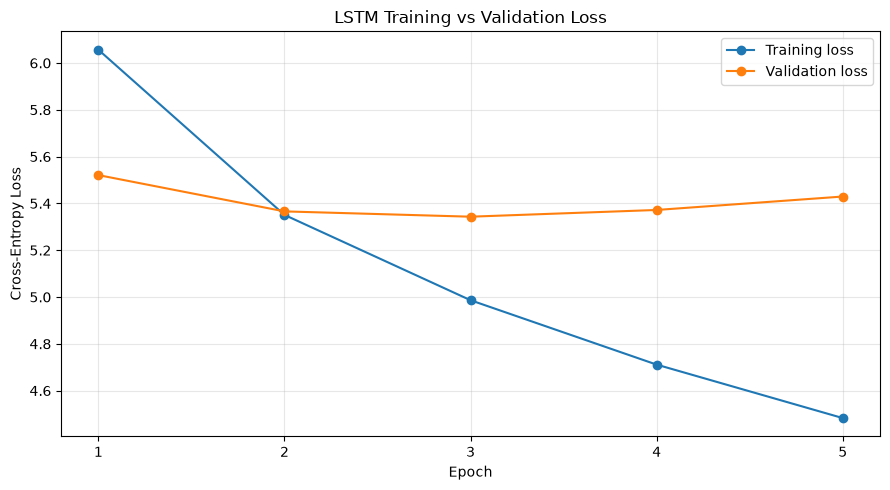

In [73]:

import matplotlib.pyplot as plt

# Include epoch 1 metrics, then add results from epochs 2–5.
epochs = [1] + [item["epoch"] for item in training_history]

train_losses = [6.0566] + [
    item["train_loss"] for item in training_history
]

val_losses = [5.5210] + [
    item["val_loss"] for item in training_history
]

# Plot both loss curves to compare training and validation performance.
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, marker="o", label="Training loss")
plt.plot(epochs, val_losses, marker="o", label="Validation loss")

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


GRU MODEL

In [74]:

import torch
import torch.nn as nn
import torch.optim as optim

class NextWordGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256):
        super().__init__()

        # Convert each word ID into a dense vector.
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # GRU learns sequential patterns from the word vectors.
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Convert the final GRU output into vocabulary scores.
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        # Shape: [batch_size, sequence_length, embedding_dim]
        embedded = self.embedding(x)

        # Process the input sequence.
        gru_output, hidden_state = self.gru(embedded)

        # Use the output corresponding to the final input word.
        last_output = gru_output[:, -1, :]

        # Return scores for all possible next words.
        logits = self.fc(last_output)
        return logits


# Initialize a fresh GRU with the same vocabulary and dimensions as the LSTM.
gru_model = NextWordGRU(vocab_size).to(device)

# Use the same loss function and learning rate for a fair comparison.
gru_criterion = nn.CrossEntropyLoss()
gru_optimizer = optim.Adam(gru_model.parameters(), lr=0.001)

# Display the architecture and parameter count.
gru_parameters = sum(
    parameter.numel() for parameter in gru_model.parameters()
)

print(gru_model)
print(f"\nGRU parameters: {gru_parameters:,}")


NextWordGRU(
  (embedding): Embedding(30000, 128)
  (gru): GRU(128, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=30000, bias=True)
)

GRU parameters: 11,846,448


In [75]:

import time

# Store training and validation metrics for each GRU epoch.
gru_history = []

# Train the GRU for five complete epochs.
for epoch in range(1, 6):

    # ---------------- TRAINING ----------------
    gru_model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    start_time = time.time()

    # Learn from every batch in the training dataset.
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients before calculating new ones.
        gru_optimizer.zero_grad()

        # Predict the next word and calculate the error.
        predictions = gru_model(X_batch)
        loss = gru_criterion(predictions, y_batch)

        # Backpropagate the error and update the weights.
        loss.backward()
        gru_optimizer.step()

        # Accumulate metrics across all training batches.
        batch_size = y_batch.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            predictions.argmax(dim=1) == y_batch
        ).sum().item()
        total_examples += batch_size

    # Calculate average training metrics.
    train_loss = total_loss / total_examples
    train_accuracy = total_correct / total_examples
    train_minutes = (time.time() - start_time) / 60

    # ---------------- VALIDATION ----------------
    gru_model.eval()

    val_loss_total = 0.0
    val_top1_correct = 0
    val_top5_correct = 0
    val_examples = 0

    # Evaluate without updating model weights.
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = gru_model(X_batch)
            loss = gru_criterion(predictions, y_batch)

            batch_size = y_batch.size(0)
            val_loss_total += loss.item() * batch_size

            # Count correct first-choice predictions.
            val_top1_correct += (
                predictions.argmax(dim=1) == y_batch
            ).sum().item()

            # Count examples where the correct word is in the top five.
            top5_ids = predictions.topk(5, dim=1).indices
            val_top5_correct += (
                top5_ids == y_batch.unsqueeze(1)
            ).any(dim=1).sum().item()

            val_examples += batch_size

    # Calculate validation metrics.
    val_loss = val_loss_total / val_examples
    val_top1 = val_top1_correct / val_examples
    val_top5 = val_top5_correct / val_examples

    # Save the results for comparison and plotting.
    gru_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_top1_accuracy": val_top1,
        "val_top5_accuracy": val_top5,
        "training_minutes": train_minutes
    })

    # Report progress after each epoch.
    print(f"\nEpoch {epoch}/5")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Training accuracy: {train_accuracy:.2%}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation top-1 accuracy: {val_top1:.2%}")
    print(f"Validation top-5 accuracy: {val_top5:.2%}")
    print(f"Training time: {train_minutes:.2f} minutes")



Epoch 1/5
Training loss: 6.0228
Training accuracy: 16.61%
Validation loss: 5.4996
Validation top-1 accuracy: 19.69%
Validation top-5 accuracy: 38.77%
Training time: 4.77 minutes

Epoch 2/5
Training loss: 5.2776
Training accuracy: 20.15%
Validation loss: 5.3834
Validation top-1 accuracy: 20.80%
Validation top-5 accuracy: 40.21%
Training time: 5.30 minutes

Epoch 3/5
Training loss: 4.8521
Training accuracy: 21.86%
Validation loss: 5.4048
Validation top-1 accuracy: 20.97%
Validation top-5 accuracy: 40.46%
Training time: 6.42 minutes

Epoch 4/5
Training loss: 4.5251
Training accuracy: 23.35%
Validation loss: 5.4847
Validation top-1 accuracy: 21.00%
Validation top-5 accuracy: 40.24%
Training time: 6.22 minutes

Epoch 5/5
Training loss: 4.2592
Training accuracy: 25.00%
Validation loss: 5.5801
Validation top-1 accuracy: 20.69%
Validation top-5 accuracy: 39.97%
Training time: 6.02 minutes


Compare LSTM vs GRU

Best validation results:


,Model,Best epoch,Validation loss,Top-1 accuracy,Top-5 accuracy
0,LSTM,3,5.3433,21.35,40.90
1,GRU,2,5.3834,20.80,40.21


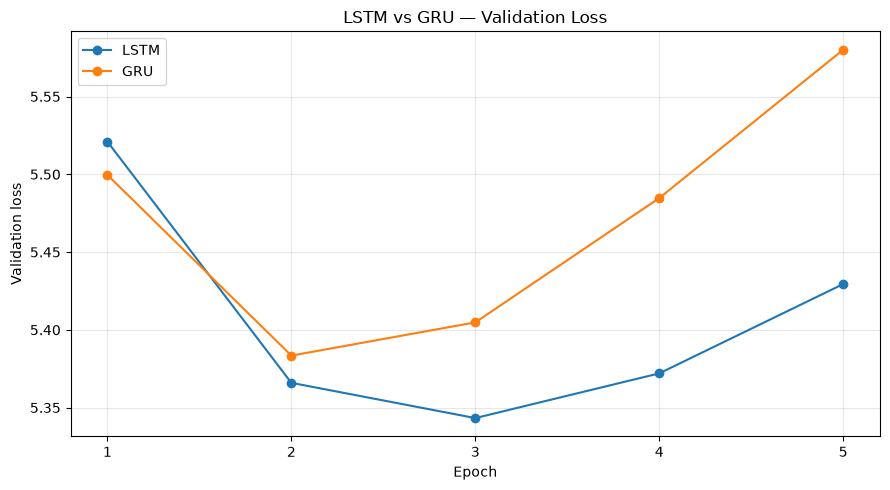

In [76]:

import pandas as pd
import matplotlib.pyplot as plt

# Find the epoch with the lowest validation loss for each model.
best_lstm = min(training_history, key=lambda item: item["val_loss"])
best_gru = min(gru_history, key=lambda item: item["val_loss"])

# Build a comparison table using each model's best validation epoch.
comparison = pd.DataFrame([
    {
        "Model": "LSTM",
        "Best epoch": best_lstm["epoch"],
        "Validation loss": best_lstm["val_loss"],
        "Top-1 accuracy": best_lstm["val_top1_accuracy"],
        "Top-5 accuracy": best_lstm["val_top5_accuracy"]
    },
    {
        "Model": "GRU",
        "Best epoch": best_gru["epoch"],
        "Validation loss": best_gru["val_loss"],
        "Top-1 accuracy": best_gru["val_top1_accuracy"],
        "Top-5 accuracy": best_gru["val_top5_accuracy"]
    }
])

# Format percentages for easier reading.
comparison["Top-1 accuracy"] = (
    comparison["Top-1 accuracy"] * 100
).round(2)
comparison["Top-5 accuracy"] = (
    comparison["Top-5 accuracy"] * 100
).round(2)
comparison["Validation loss"] = comparison["Validation loss"].round(4)

print("Best validation results:")
display(comparison)

# Plot validation loss for both models across their training epochs.
plt.figure(figsize=(9, 5))

# Include the previously completed LSTM epoch 1.
lstm_epochs = [1] + [item["epoch"] for item in training_history]
lstm_losses = [5.5210] + [
    item["val_loss"] for item in training_history
]

plt.plot(lstm_epochs, lstm_losses, marker="o", label="LSTM")
plt.plot(
    [item["epoch"] for item in gru_history],
    [item["val_loss"] for item in gru_history],
    marker="o",
    label="GRU"
)

plt.title("LSTM vs GRU — Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


save best gru and lstm checkpoint

In [77]:

from pathlib import Path
import copy
import torch

# Ensure the checkpoint folder exists.
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# The best LSTM epoch was identified from training_history.
best_lstm = min(training_history, key=lambda item: item["val_loss"])

# The best GRU epoch was identified from gru_history.
best_gru = min(gru_history, key=lambda item: item["val_loss"])

# Save the current model states as recovery checkpoints.
# Note: these are the final in-memory weights, not necessarily
# the best-epoch weights, unless the best epoch was the last one.
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "word_to_id": word_to_id,
    "id_to_word": id_to_word,
    "vocab_size": vocab_size,
    "sequence_length": sequence_length,
    "embedding_dim": 128,
    "hidden_dim": 256,
    "epoch": 5,
    "best_validation_loss": best_lstm["val_loss"],
    "training_history": training_history
}, models_dir / "lstm_wikitext_20k_epoch5.pt")

torch.save({
    "model_state_dict": gru_model.state_dict(),
    "optimizer_state_dict": gru_optimizer.state_dict(),
    "word_to_id": word_to_id,
    "id_to_word": id_to_word,
    "vocab_size": vocab_size,
    "sequence_length": sequence_length,
    "embedding_dim": 128,
    "hidden_dim": 256,
    "epoch": 5,
    "best_validation_loss": best_gru["val_loss"],
    "training_history": gru_history
}, models_dir / "gru_wikitext_20k_epoch5.pt")

print("Both final-epoch checkpoints saved.")
print(f"Best LSTM validation loss: {best_lstm['val_loss']:.4f}")
print(f"Best GRU validation loss: {best_gru['val_loss']:.4f}")


Both final-epoch checkpoints saved.
Best LSTM validation loss: 5.3433
Best GRU validation loss: 5.3834


In [78]:

import pandas as pd

# Locate the official WikiText-103 test file.
test_path = PROJECT_ROOT / "data" / "test-00000-of-00001.parquet"

# Load only the text column to keep memory usage low.
test_df = pd.read_parquet(test_path, columns=["text"])

# Apply the same conservative cleaning used for training.
test_records = test_df["text"].map(clean_text).tolist()

# Remove empty records, keeping each article/record separate.
test_records = [text for text in test_records if text]

# Count words in the test set.
test_token_count = sum(len(text.split()) for text in test_records)

print(f"Non-empty test records: {len(test_records):,}")
print(f"Test tokens: {test_token_count:,}")
print("\nExample test record:")
print(test_records[0][:300])


Non-empty test records: 2,891
Test tokens: 241,211

Example test record:
= Robert Boulter =


In [79]:

# Convert the test records into input sequences and next-word targets.
# Use the existing training vocabulary; do not build a new one from test data.
X_test, y_test = create_sequences(
    test_records,
    word_to_id,
    sequence_length
)

# Convert the sequences into PyTorch tensors.
X_test_tensor = torch.tensor(X_test, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Create a loader so test examples can be evaluated in manageable batches.
test_dataset = torch.utils.data.TensorDataset(
    X_test_tensor, y_test_tensor
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

# Count test targets that are outside the training vocabulary.
unknown_target_count = sum(
    1 for target_id in y_test if target_id == word_to_id["<UNK>"]
)

print(f"Test examples: {len(test_dataset):,}")
print(f"Test batches: {len(test_loader):,}")
print(
    f"Unknown targets: {unknown_target_count:,} "
    f"({unknown_target_count / len(y_test):.2%})"
)
print(f"Input tensor shape: {tuple(X_test_tensor.shape)}")
print(f"Target tensor shape: {tuple(y_test_tensor.shape)}")


Test examples: 227,204
Test batches: 888
Unknown targets: 12,883 (5.67%)
Input tensor shape: (227204, 5)
Target tensor shape: (227204,)


Retrain LSTM with best-checkpoint tracking

In [80]:

import copy
import time
import torch

# Keep a separate record of this retraining run.
lstm_best_val_loss = float("inf")
lstm_best_epoch = 0
lstm_best_state = None
lstm_retrain_history = []

# Train for up to five epochs, starting from the current model.
for epoch in range(1, 6):

    # ---------------- TRAINING ----------------
    model.train()
    total_loss = 0.0
    total_examples = 0
    start_time = time.time()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear gradients, predict, calculate loss, and update weights.
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

        # Accumulate the average training loss.
        batch_size = y_batch.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    train_loss = total_loss / total_examples

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss_total = 0.0
    val_examples = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            batch_size = y_batch.size(0)
            val_loss_total += loss.item() * batch_size
            val_examples += batch_size

    val_loss = val_loss_total / val_examples

    # Record this epoch's losses.
    lstm_retrain_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    # Save a copy of the weights whenever validation loss improves.
    if val_loss < lstm_best_val_loss:
        lstm_best_val_loss = val_loss
        lstm_best_epoch = epoch
        lstm_best_state = copy.deepcopy(model.state_dict())

        # Save the best weights and associated metadata immediately.
        torch.save({
            "epoch": lstm_best_epoch,
            "model_state_dict": lstm_best_state,
            "word_to_id": word_to_id,
            "id_to_word": id_to_word,
            "vocab_size": vocab_size,
            "sequence_length": sequence_length,
            "embedding_dim": 128,
            "hidden_dim": 256,
            "validation_loss": lstm_best_val_loss
        }, models_dir / "lstm_best.pt")

    print(
        f"Epoch {epoch}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Elapsed: {(time.time() - start_time) / 60:.2f} min"
    )

# Restore the best validation weights in the live model.
model.load_state_dict(lstm_best_state)

print(f"\nBest LSTM epoch: {lstm_best_epoch}")
print(f"Best LSTM validation loss: {lstm_best_val_loss:.4f}")
print("Best LSTM weights saved to models/lstm_best.pt")


Epoch 1/5 | Train loss: 4.2839 | Validation loss: 5.5015 | Elapsed: 4.43 min
Epoch 2/5 | Train loss: 4.1071 | Validation loss: 5.5832 | Elapsed: 5.01 min
Epoch 3/5 | Train loss: 3.9471 | Validation loss: 5.6700 | Elapsed: 5.50 min
Epoch 4/5 | Train loss: 3.8018 | Validation loss: 5.7552 | Elapsed: 5.38 min
Epoch 5/5 | Train loss: 3.6697 | Validation loss: 5.8520 | Elapsed: 4.88 min

Best LSTM epoch: 1
Best LSTM validation loss: 5.5015
Best LSTM weights saved to models/lstm_best.pt


Retrain GRU with best-checkpoint tracking

In [81]:

import copy
import time
import torch

# Track the best GRU checkpoint from this fine-tuning run.
gru_best_val_loss = float("inf")
gru_best_epoch = 0
gru_best_state = None
gru_retrain_history = []

# Fine-tune the existing GRU for up to five epochs.
for epoch in range(1, 6):

    # ---------------- TRAINING ----------------
    gru_model.train()
    total_loss = 0.0
    total_examples = 0
    start_time = time.time()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients and calculate new predictions.
        gru_optimizer.zero_grad()
        predictions = gru_model(X_batch)
        loss = gru_criterion(predictions, y_batch)

        # Update the GRU parameters using backpropagation.
        loss.backward()
        gru_optimizer.step()

        # Accumulate total loss for an accurate epoch average.
        batch_size = y_batch.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    train_loss = total_loss / total_examples

    # ---------------- VALIDATION ----------------
    gru_model.eval()
    val_loss_total = 0.0
    val_examples = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = gru_model(X_batch)
            loss = gru_criterion(predictions, y_batch)

            batch_size = y_batch.size(0)
            val_loss_total += loss.item() * batch_size
            val_examples += batch_size

    val_loss = val_loss_total / val_examples

    # Keep this epoch's results.
    gru_retrain_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    # Save weights whenever validation loss improves.
    if val_loss < gru_best_val_loss:
        gru_best_val_loss = val_loss
        gru_best_epoch = epoch
        gru_best_state = copy.deepcopy(gru_model.state_dict())

        torch.save({
            "epoch": gru_best_epoch,
            "model_state_dict": gru_best_state,
            "word_to_id": word_to_id,
            "id_to_word": id_to_word,
            "vocab_size": vocab_size,
            "sequence_length": sequence_length,
            "embedding_dim": 128,
            "hidden_dim": 256,
            "validation_loss": gru_best_val_loss
        }, models_dir / "gru_best.pt")

    print(
        f"Epoch {epoch}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Elapsed: {(time.time() - start_time) / 60:.2f} min"
    )

# Restore the best weights from this run.
gru_model.load_state_dict(gru_best_state)

print(f"\nBest GRU epoch: {gru_best_epoch}")
print(f"Best GRU validation loss: {gru_best_val_loss:.4f}")
print("Best GRU weights saved to models/gru_best.pt")


Epoch 1/5 | Train loss: 4.0384 | Validation loss: 5.6860 | Elapsed: 4.70 min
Epoch 2/5 | Train loss: 3.8526 | Validation loss: 5.7957 | Elapsed: 4.95 min
Epoch 3/5 | Train loss: 3.6969 | Validation loss: 5.9005 | Elapsed: 5.80 min
Epoch 4/5 | Train loss: 3.5641 | Validation loss: 6.0077 | Elapsed: 5.97 min
Epoch 5/5 | Train loss: 3.4502 | Validation loss: 6.1064 | Elapsed: 5.84 min

Best GRU epoch: 1
Best GRU validation loss: 5.6860
Best GRU weights saved to models/gru_best.pt


Final test evaluation

In [82]:

import torch
import pandas as pd

# Evaluate a model without updating its weights.
def evaluate_on_test(model_to_evaluate, model_name):
    model_to_evaluate.eval()

    total_loss = 0.0
    total_correct = 0
    total_top5_correct = 0
    total_examples = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            # Move the batch to the same device as the model.
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Get predictions and calculate loss.
            logits = model_to_evaluate(X_batch)
            loss = criterion(logits, y_batch)

            batch_size = y_batch.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

            # Top-1 accuracy: the single most likely word.
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == y_batch).sum().item()

            # Top-5 accuracy: the correct word appears among five predictions.
            top5_predictions = logits.topk(5, dim=1).indices
            total_top5_correct += (
                top5_predictions == y_batch.unsqueeze(1)
            ).any(dim=1).sum().item()

    return {
        "Model": model_name,
        "Test Loss": total_loss / total_examples,
        "Top-1 Accuracy (%)": 100 * total_correct / total_examples,
        "Top-5 Accuracy (%)": 100 * total_top5_correct / total_examples
    }


# Evaluate the best checkpoints restored in the previous cells.
lstm_test_results = evaluate_on_test(model, "LSTM")
gru_test_results = evaluate_on_test(gru_model, "GRU")

# Display the final test comparison.
final_test_results = pd.DataFrame([
    lstm_test_results,
    gru_test_results
])

display(final_test_results.round(4))


,Model,Test Loss,Top-1 Accuracy (%),Top-5 Accuracy (%)
0,LSTM,5.4936,21.1136,40.8109
1,GRU,5.6770,20.4305,39.8633


Test your model with custom text

In [83]:

# Predict the five most likely next words for a given input sentence.
def predict_next_words(text, model_to_use=model, top_k=5):
    model_to_use.eval()

    # Apply the same basic cleaning used for the dataset.
    cleaned_text = clean_text(text)
    words = cleaned_text.split()

    # The model expects the most recent five words.
    words = words[-sequence_length:]

    # Convert words to IDs, using UNK for words outside the vocabulary.
    input_ids = [
        word_to_id.get(word, word_to_id["<UNK>"])
        for word in words
    ]

    # Pad shorter inputs on the left so the input length is five.
    input_ids = [word_to_id["<UNK>"]] * (
        sequence_length - len(input_ids)
    ) + input_ids

    # Convert the input into a tensor and run the model.
    input_tensor = torch.tensor(
        [input_ids], dtype=torch.long, device=device
    )

    with torch.no_grad():
        logits = model_to_use(input_tensor)
        probabilities = torch.softmax(logits, dim=1)
        top_probabilities, top_ids = torch.topk(
            probabilities, k=top_k, dim=1
        )

    # Convert predicted IDs back into words.
    results = []
    for word_id, probability in zip(
        top_ids[0].tolist(), top_probabilities[0].tolist()
    ):
        results.append({
            "Predicted next word": id_to_word[word_id],
            "Probability (%)": round(probability * 100, 2)
        })

    return pd.DataFrame(results)


# Try your own sentence.
display(predict_next_words("machine learning is becoming more"))


,Predicted next word,Probability (%)
0,closely,13.28
1,vulnerable,10.53
2,likely,3.36
3,costly,2.39
4,common,2.13


In [85]:

# Generate several words one after another using the LSTM model.
def generate_text(prompt, num_words=10, model_to_use=model):
    model_to_use.eval()

    # Start with the text supplied by the user.
    generated_text = clean_text(prompt)

    for _ in range(num_words):
        # Keep only the latest five words for the model.
        words = generated_text.split()[-sequence_length:]

        # Convert words into vocabulary IDs.
        input_ids = [
            word_to_id.get(word, word_to_id["<UNK>"])
            for word in words
        ]

        # Pad short inputs to the required sequence length.
        input_ids = (
            [word_to_id["<UNK>"]] * (sequence_length - len(input_ids))
            + input_ids
        )

        input_tensor = torch.tensor(
            [input_ids], dtype=torch.long, device=device
        )

        # Predict the next word.
        with torch.no_grad():
            logits = model_to_use(input_tensor)
            next_word_id = logits.argmax(dim=1).item()

        # Convert the predicted ID into a word.
        next_word = id_to_word[next_word_id]

        # Stop if the model predicts an unknown token.
        if next_word == "<UNK>":
            break

        # Append the predicted word to the generated text.
        generated_text += " " + next_word

    return generated_text


# Try different prompts.
print(generate_text("artificial intelligence is changing", num_words=10))
print(generate_text("machine learning models can", num_words=10))
print(generate_text("the history of the world", num_words=10))


artificial intelligence is changing the
machine learning models can be used to be the most important lesson of the
the history of the world . The


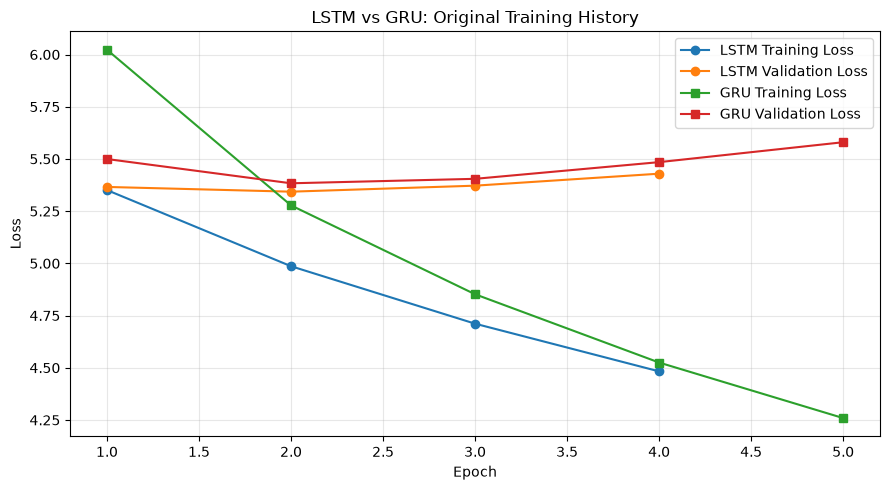

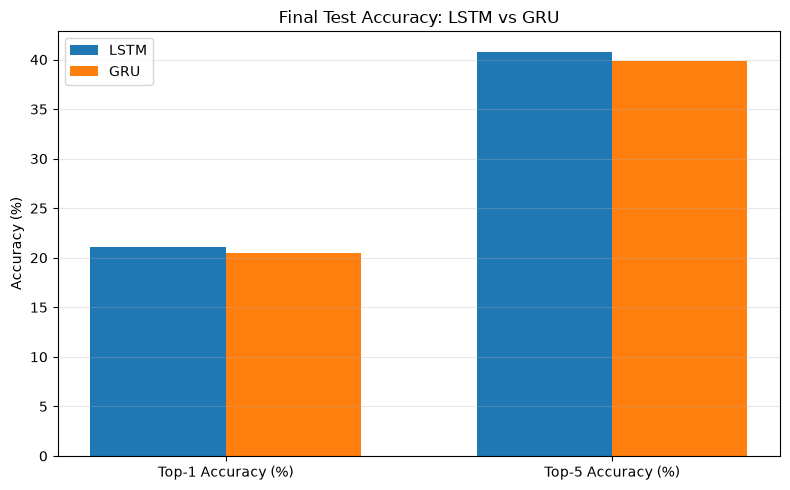

Saved graphs and test metrics in the models folder.


In [86]:

import matplotlib.pyplot as plt
from pathlib import Path

# Make sure the output folder exists.
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Plot training and validation loss for the original training runs.
# The additional fine-tuning runs are plotted separately below.
plt.figure(figsize=(9, 5))

# Include the original five-epoch histories.
lstm_epochs = list(range(1, len(training_history) + 1))
gru_epochs = list(range(1, len(gru_history) + 1))

plt.plot(
    lstm_epochs,
    [item["train_loss"] for item in training_history],
    marker="o",
    label="LSTM Training Loss"
)
plt.plot(
    lstm_epochs,
    [item["val_loss"] for item in training_history],
    marker="o",
    label="LSTM Validation Loss"
)
plt.plot(
    gru_epochs,
    [item["train_loss"] for item in gru_history],
    marker="s",
    label="GRU Training Loss"
)
plt.plot(
    gru_epochs,
    [item["val_loss"] for item in gru_history],
    marker="s",
    label="GRU Validation Loss"
)

plt.title("LSTM vs GRU: Original Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(models_dir / "training_loss_comparison.png", dpi=300)
plt.show()

# 2. Plot final test metrics for both models.
metrics = ["Top-1 Accuracy (%)", "Top-5 Accuracy (%)"]
x = range(len(metrics))
width = 0.35

lstm_values = [
    lstm_test_results["Top-1 Accuracy (%)"],
    lstm_test_results["Top-5 Accuracy (%)"]
]
gru_values = [
    gru_test_results["Top-1 Accuracy (%)"],
    gru_test_results["Top-5 Accuracy (%)"]
]

plt.figure(figsize=(8, 5))
plt.bar([i - width / 2 for i in x], lstm_values, width, label="LSTM")
plt.bar([i + width / 2 for i in x], gru_values, width, label="GRU")

plt.xticks(list(x), metrics)
plt.ylabel("Accuracy (%)")
plt.title("Final Test Accuracy: LSTM vs GRU")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(models_dir / "test_accuracy_comparison.png", dpi=300)
plt.show()

# 3. Save the final test metrics as a CSV file.
final_test_results.to_csv(
    models_dir / "final_test_results.csv",
    index=False
)

print("Saved graphs and test metrics in the models folder.")
